<h1><center> Le lissage exponentielle et les méthodes rapides

In [20]:
import numpy as np
import pandas as pd

np.random.seed(42)

In [21]:
# Génération de la série brute


dates = pd.date_range(start="2022-01-01", periods=48, freq="MS") # 4 ans

trend = np.linspace(100, 250, 48) # tendance linéaire


seasonality = np.array([1.1, 1.0, 0.9, 0.95, 1.05, 1.2, 1.4, 1.1, 1.0, 0.95, 1.05, 1.3]) # sasionalité annuelle (période = 12 mois)
seasonality_48 = np.tile(seasonality, 4)

# Combinaison tendance + saisonnalité + un peu de bruit aléatoire
noise = np.random.normal(0, 4, 48)
sales = (trend * seasonality_48) + noise





In [22]:
# DataFrame final

df = pd.DataFrame({"Ventes": sales}, index=dates)
df.head()

,Ventes
2022-01-01,111.986857
2022-02-01,102.638432
2022-03-01,98.335435
2022-04-01,110.187864
2022-05-01,117.467642


In [23]:
import matplotlib.pyplot as plt

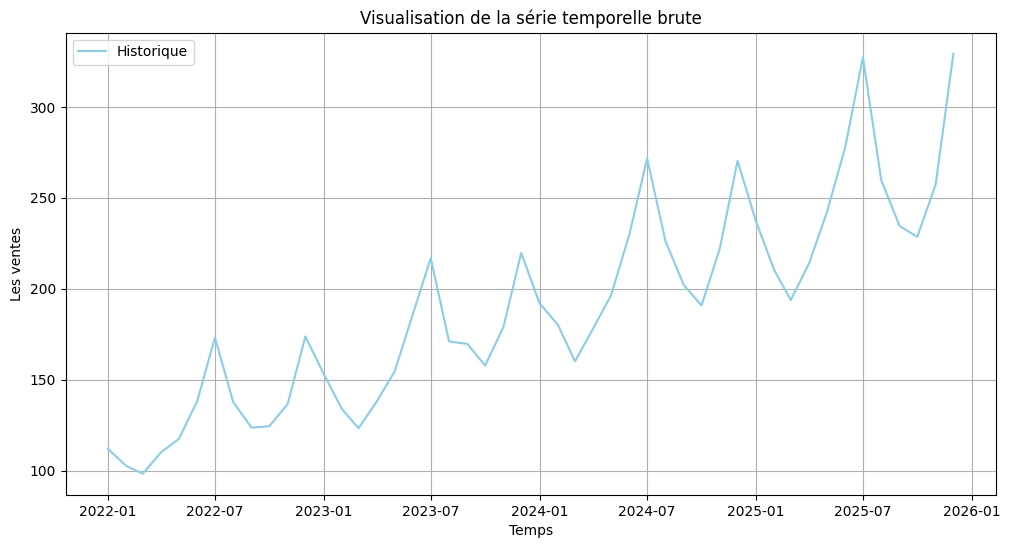

In [24]:
# Visualisation de la série temporelle brute

plt.figure(figsize=(12,6))
plt.plot(df.index, df["Ventes"], color= "skyblue", label= "Historique")
plt.xlabel("Temps")
plt.ylabel("Les ventes")
plt.title("Visualisation de la série temporelle brute")
plt.grid(True)
plt.legend()
plt.show()


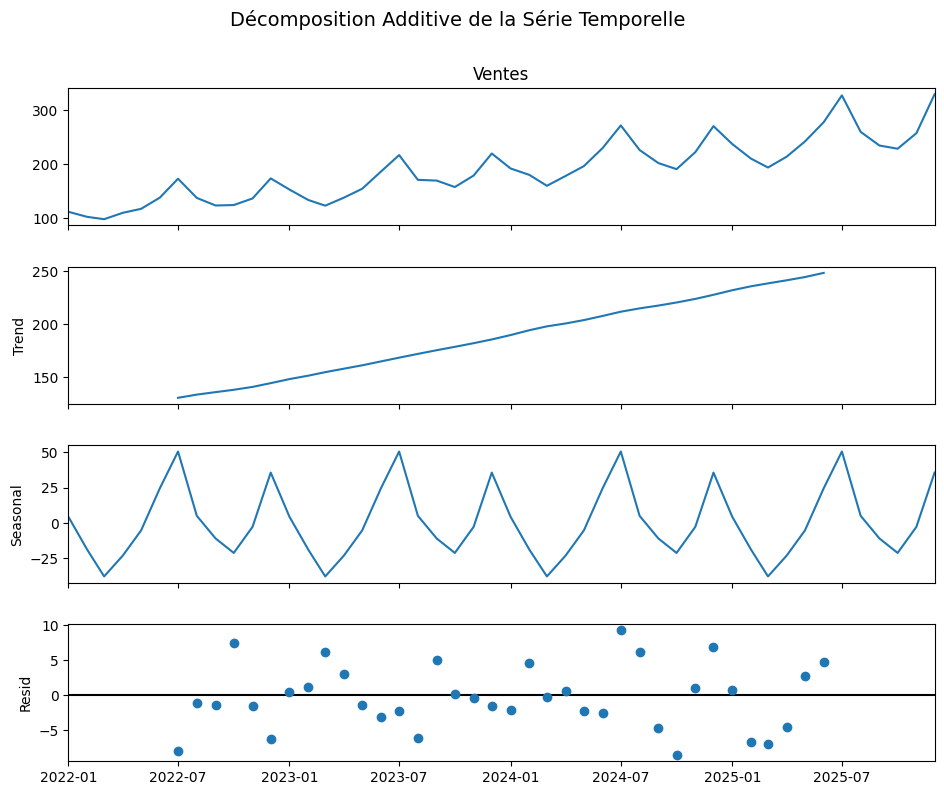

In [25]:
# Pour voir la tendance et la saisonalité

from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(df["Ventes"], model= "additive", period= 12)

fig = decomposition.plot()
fig.set_size_inches(10, 8)
plt.suptitle("Décomposition Additive de la Série Temporelle", fontsize=14, y=1.02)
plt.show()

## La famille de modèles : Lissage Exponentielle

Cette famille ne cherche pas de coefficients autorégressifs complexes comme dans ARIMA. 

Elle part d'un constat simple : les données d'hier pèsent plus lourd que les données d'il y a 3 ans, et on ajuste le niveau, la tendance et la saisonnalité au fil de du temps.

<img src="image.png">

### Entrainement du modèle Holt-Winters

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model = ExponentialSmoothing(
                            df["Ventes"],
                            trend= 'add', # additive
                            seasonal= 'mul',
                            seasonal_periods= 12
                            ).fit() # !!!!!!!!!


In [27]:
# Inspection des paramétres du modèle

model.params_formatted

,name,param,optimized
smoothing_level,alpha,1.490116e-08,True
smoothing_trend,beta,2.793529e-09,True
smoothing_seasonal,gamma,0.000000e+00,True
initial_level,l.0,1.268156e+02,True
initial_trend,b.0,4.112861e+00,True
initial_seasons.0,s.0,8.465113e-01,True
initial_seasons.1,s.1,7.495782e-01,True
initial_seasons.2,s.2,6.736998e-01,True
initial_seasons.3,s.3,7.357535e-01,True
initial_seasons.4,s.4,8.045052e-01,True


In [31]:
# Faire des prévisions pour les 12 prochains mois

forecast_12months = model.forecast(12)

forecast_12months

2026-01-01    277.948450
2026-02-01    249.203771
2026-03-01    226.748191
2026-04-01    250.659750
2026-05-01    277.391192
2026-06-01    322.136193
2026-07-01    379.449121
2026-08-01    303.619811
2026-09-01    276.630225
2026-10-01    264.385799
2026-11-01    298.702043
2026-12-01    371.652120
Freq: MS, dtype: float64

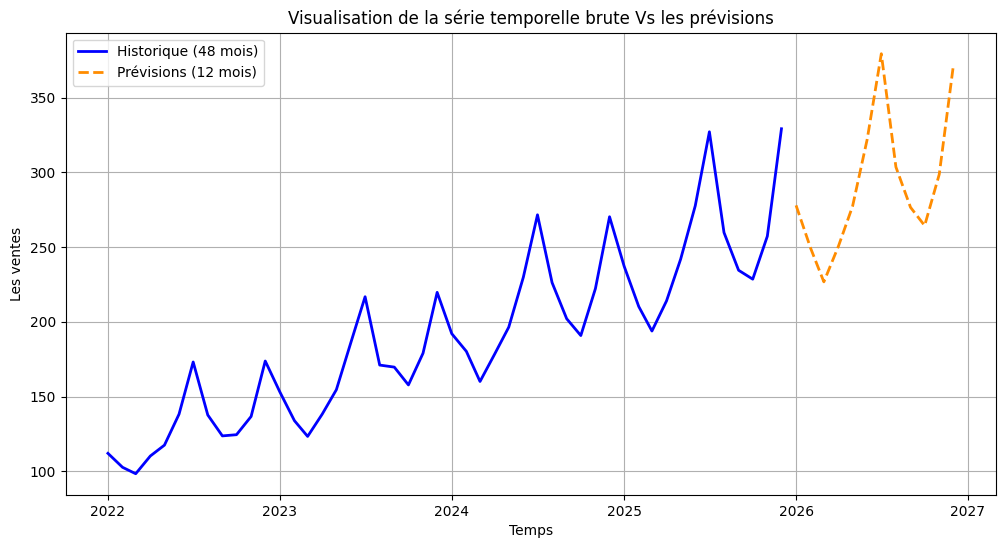

In [35]:
# Visualisation des résultats et des prévisions

plt.figure(figsize=(12,6))
plt.plot(df.index, df["Ventes"], color= "blue", label= "Historique (48 mois)", linewidth= 2)
plt.plot(forecast_12months.index, forecast_12months, color= "darkorange", label= "Prévisions (12 mois)", linewidth= 2, linestyle= "--")

plt.xlabel("Temps")
plt.ylabel("Les ventes")
plt.title("Visualisation de la série temporelle brute Vs les prévisions")
plt.grid(True)
plt.legend()
plt.show()